# Zadanie 2A — BloodMNIST

**Cel:** przygotuj dane obrazowe, wytrenuj i oceń model klasyfikujący osiem typów komórek krwi, a następnie zastosuj samodzielnie wybraną metodę wyjaśniania predykcji.

In [164]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.transforms import v2
import torchvision
import torch.optim as optim

In [165]:
DATA_DIR = Path("data/zadanie-2a")
DATA_DIR.mkdir(parents=True, exist_ok=True)

data_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-2A",
    filename="original/bloodmnist.npz",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
data = np.load(data_path)
print(data.files)

['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']


## A — Poznanie i przygotowanie danych

Sprawdź strukturę obrazów, kanały, klasy, liczebności i jakość danych. Zachowaj oficjalne podziały treningowy, walidacyjny i testowy. Wykonaj preprocessing i augmentację; wszystkie decyzje zależne od danych podejmuj wyłącznie na zbiorze treningowym.

In [166]:
bloodmnist_path = Path.cwd() / "data" / "zadanie-2a" / "original" / "bloodmnist.npz"
data = np.load(bloodmnist_path)
X_train = data["train_images"]
X_val = data["val_images"]
X_test = data["test_images"]
y_train = data["train_labels"]
y_val = data["val_labels"]
y_test = data["test_labels"]


In [167]:
#obrazy mają wymiary 28x28 i 3 kanały kolorów (RGB)
X_train.shape, X_val.shape, X_test.shape

((11959, 28, 28, 3), (1712, 28, 28, 3), (3421, 28, 28, 3))

In [168]:
#zbiór danych nie jest idealnie zbalansowany. Klasy 6 jest prawie 3 razy więcej niż klasy 4. Nie przeszkadza
#to jednak bardzo w uczeniu modelu
classes_counts = pd.DataFrame(y_train).value_counts()
n_classes = classes_counts.shape[0]
classes_counts

0
6    2330
1    2181
3    2026
7    1643
2    1085
5     993
0     852
4     849
Name: count, dtype: int64

In [169]:
#nie ma brakujących danych
print(np.isnan(X_train).sum())
print(np.isnan(y_train).sum())


0
0


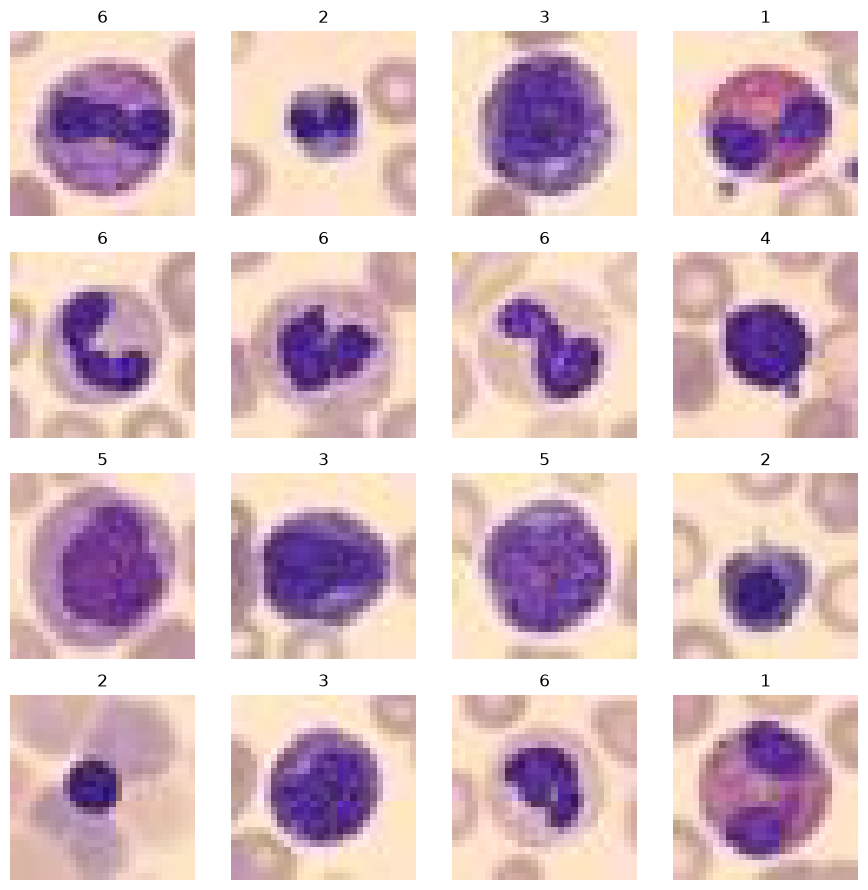

In [170]:
from random import randint
fig = plt.figure(figsize=(9, 9))
for i in range(1, 16 + 1):
    ind = randint(0, len(X_train))
    fig.add_subplot(4, 4, i)
    plt.imshow(X_train[ind])
    plt.title(y_train[ind][0])
    plt.axis("off")

plt.tight_layout()

In [171]:
unique_X_train_indexes = np.unique(X_train, axis=0, return_index=True)[1]
X_train = X_train[unique_X_train_indexes]
y_train = y_train[unique_X_train_indexes]

In [172]:
#zrezygnowałem z normalizacji, ponieważ nie poprawia to znacząco treningu, a chciałem żeby w sekcji C
#wyświetlały się obrazy bez transformacji
train_transforms = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomRotation(degrees=10),
    v2.RandomAffine(degrees=0, translate=(0.05, 0.05)),
    v2.Normalize(mean=(X_train / 255.0).mean(axis=(0, 1, 2)), std=(X_train / 255.0).std(axis=(0, 1, 2))),
])

test_transforms = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=(X_train / 255.0).mean(axis=(0, 1, 2)), std=(X_train / 255.0).std(axis=(0, 1, 2))),
])

In [173]:
class BloodDataset(Dataset):
    def __init__(self, images, labels, transforms):
        self.images = images
        self.labels = labels
        self.transform = transforms
        super().__init__()

    def __len__(self) -> int:
        return self.images.shape[0]

    def __getitem__(self, index: int) -> tuple[torchvision.tv_tensors.Image, torch.Tensor]:
        image = self.images[index]
        label = self.labels[index]

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)


In [174]:
train_dataset = BloodDataset(X_train, y_train, transforms=train_transforms)
val_dataset = BloodDataset(X_val, y_val, transforms=test_transforms)
test_dataset = BloodDataset(X_test, y_test, transforms=test_transforms)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32)
test_loader = DataLoader(test_dataset, batch_size=32)

## B — Modelowanie i walidacja

Wytrenuj model wieloklasowy. Przeanalizuj architekturę, funkcję kosztu, optymalizator i sposób użycia walidacji do wyboru modelu lub zatrzymania treningu. Zbiór testowy pozostaw nietknięty do końcowej oceny.

In [175]:
from copy import deepcopy
class BloodCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128 * 28 // 4 * 28 // 4, n_classes),
        )
    def forward(self, x):
        return self.classifier(self.block2(self.block1(x)))

model = BloodCNN()

loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.002)

epochs = 10
best_model = deepcopy(model.state_dict())
best_loss = float("inf")
for epoch in range(epochs):
    model.train()
    train_loss = 0
    for X, y in train_loader:
        y_pred = model(X)
        y = y.squeeze()
        loss = loss_fn(y_pred, y)
        train_loss += loss
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    train_loss = train_loss / len(train_loader)

    model.eval()
    val_loss = 0
    correct = 0
    total = 0
    with torch.inference_mode():
        for X, y in val_loader:
            y_preds = model(X)
            y = y.squeeze()
            loss = loss_fn(y_preds, y)
            val_loss += loss.item()
            _, outputs = torch.max(y_preds, dim=1)
            correct += (outputs == y).sum()
            total += y.shape[0]
            
    val_loss = val_loss / len(val_loader)
    acc = correct / total
    print(f"epoch: {epoch + 1}, val_loss: {val_loss}, accuracy: {acc}")
    if val_loss < best_loss:
        best_loss = val_loss
        best_model = deepcopy(model.state_dict())
    if val_loss < 0.17:
        break
model.load_state_dict(best_model)

#architektura modelu składa się z dwóch głównych bloków oraz classifier. Oba bloki zakończone są warstwą
#MaxPool zmniejszającą dwukrotnie wymiary przestrzenne. W blokach są po dwie warstwy konwolucyjne z padding = 1
#dodającym ramkę z zerami wokół obrazu co zapobiega jego kurczeniu się, bo kernel zaczynał by od piksela
#(1, 1) i kończyłby na (n -2, n - 2) (licząc od 0). Po warstaiwe konwolucyjna jest warstwa normalizująca
#wartości, która stabilizuje i przyspiesza trening. Następnie funkcja relu wprowadza nieliniowość, co
#jest kluczowe w uczeniu się złożonych wzorców przez każdą sieć neuronową.
#W classifier jest warstwa flatten, która spłaszcza poprzednią warstwę do jednego wymiaru,
#następnie warstwa dropout wyłącza 30% neuronów, co wymusza na sieci neuronowej uczenie się bardziej
#uniwersalnych wzorców. Na koniec wprowadzona jest warstwa liniowa z logitami dla każdej klasy.
#Funkcja straty to cross entropy loss, popularna dla klasyfikacji wieloklasowej. Przekształca logity używając
#softmax na prawdopodobieństwa i używa log loss dla wielu klas żeby wyznaczyć błąd. Wybrany optymalizator to
#Adam, który okazał się radzić sobie znacznie lepiej niż SGD. Na podstaiwe walidacji wybierany jest model
#który miał najmniejszą wartość funkcji straty na danych walidacyjnych. Zastosowałem również warunek stopu
#który zatrzymuje proces uczenia gdy wartość funkcji straty na dalnych treningowych jest < 0.17.
#Na koniec zaznaczę że nie pisałem device-agnostic code, ponieważ nie używałem GPU,
#ale w celu użycie GPU trzeba zdefiniować zmienną device = "cuda" if torch.cuda.is_available() else "cpu"
#a następnie na każdym tensorze i modelu wykonywać metodę .to(device)

epoch: 1, val_loss: 0.46471930929908045, accuracy: 0.8294392228126526
epoch: 2, val_loss: 0.31002286200722057, accuracy: 0.8925233483314514
epoch: 3, val_loss: 0.25089539373638453, accuracy: 0.9153037667274475
epoch: 4, val_loss: 0.2790963120275625, accuracy: 0.9001168012619019
epoch: 5, val_loss: 0.2154746959330859, accuracy: 0.923481285572052
epoch: 6, val_loss: 0.20331115406696443, accuracy: 0.9269859790802002
epoch: 7, val_loss: 0.19919139319271953, accuracy: 0.9339953064918518
epoch: 8, val_loss: 0.17635836962748458, accuracy: 0.9357476830482483
epoch: 9, val_loss: 0.22178114612621289, accuracy: 0.922897219657898
epoch: 10, val_loss: 0.44059516820642686, accuracy: 0.8726635575294495


<All keys matched successfully>

## C — Ocena i wyjaśnialność

Oceń wybrany model na oficjalnym zbiorze testowym, używając odpowiednich metryk wieloklasowych i analizy pomyłek. Znajdź w literaturze lub wiarygodnym źródle metodę wizualnego wyjaśniania modeli obrazowych, zastosuj ją do poprawnych i błędnych predykcji z kilku klas oraz omów jej ograniczenia. Podaj źródło.

In [176]:
model.eval()
preds = []
labels = []
with torch.inference_mode():
    for X, y in test_loader:
        y_preds = model(X)
        _, outputs = torch.max(y_preds, dim=1)
        preds += outputs.numpy().tolist()
        labels += y.squeeze().numpy().tolist()

In [177]:
print(f"f1 macro score of the model is {f1_score(labels, preds, average="macro")}")

f1 macro score of the model is 0.9234191412593056


In [178]:
print(classification_report(labels, preds))

              precision    recall  f1-score   support

           0       0.96      0.85      0.90       244
           1       0.96      1.00      0.98       624
           2       0.98      0.93      0.95       311
           3       0.79      0.91      0.85       579
           4       0.94      0.90      0.92       243
           5       0.96      0.72      0.82       284
           6       0.96      0.97      0.97       666
           7       1.00      1.00      1.00       470

    accuracy                           0.93      3421
   macro avg       0.94      0.91      0.92      3421
weighted avg       0.94      0.93      0.93      3421



In [179]:
cm = confusion_matrix(labels, preds)
print(cm)

[[207   8   0  26   3   0   0   0]
 [  0 624   0   0   0   0   0   0]
 [  1   0 288  14   3   0   4   1]
 [  5  13   1 527   3   7  23   0]
 [  0   0   5  18 219   1   0   0]
 [  1   2   1  70   5 205   0   0]
 [  2   2   0  13   0   0 649   0]
 [  0   0   0   0   0   0   0 470]]


Text(0, 0.5, 'number')

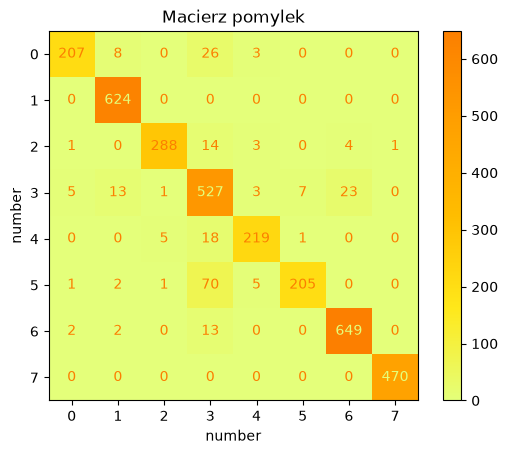

In [180]:
#wizualizacja confusionMatrix
cm_plt = ConfusionMatrixDisplay(confusion_matrix=cm)
cm_plt.plot(cmap=plt.cm.Wistia)
plt.title("Macierz pomylek")
plt.xlabel("number")
plt.ylabel("number")

In [181]:
#metoda wizualnego wyjaśniania modeli obrazowych - gradcam
#Jest to technika XAI(explainable AI). Pokazuje jakie elementy obrazu mają najwiękrzy 
#wpływ na zwiękrzenie prawdopodobieństwa wybrania konkretnej klasy
#żródła z których skorzystałem:
#artykuł https://towardsdatascience.com/grad-cam-from-scratch-with-pytorch-hooks/
#film yt https://youtu.be/_QiebC9WxOc?si=XPHEeLuDn37ZgJr6
#plik na githubie https://github.com/a-data-odyssey/XAI-for-CV/blob/main/src/gradient/grad-cam-from-scratch.ipynb
#gemini użyte do lepszego zrozumienia różnych aspektów
#Ograniczenia gradcam: gradcam bazuje na ostatniej warstwie konwolucyjnej która ma w tym przypadku pomniejszony przez
#MaxPool kształt 14x14, więc gradcam jest w stanie wskazać tylko dość szeroki region. Gradcam działa również jedynie
#dla konwolucyjnych sieci neuronowych. Ograniczeniem jest również opieranie się na wielu przybliżeniach i uproszczeniach
#(np wag dla całych map cech), mimo bardzo złożonej struktury. Może to prowadzić do błędów.
import matplotlib.pyplot as plt
import numpy as np
!uv pip install opencv-python
import cv2
import torch
import torch.nn.functional as F
from torchvision import models, transforms

# images, labels = next(iter(test_loader))
# model.eval()
# im, lab = images[0].unsqueeze(0), labels[0][0]

def plot_gradcam_heatmap(X, y):
    activations = []
    def save_activations(module, input, output):
        activations.append(output.detach().numpy().squeeze())

    gradients = []
    def save_gradients(module, grad_in, grad_out):
        gradients.append(grad_out[0][0].detach())

    hook_forward = model.block2[2].register_forward_hook(save_activations)

    hook_backward = model.block2[2].register_full_backward_hook(save_gradients)


    output = model(test_transforms(X).unsqueeze(dim=0))
    score = output[0][y]
    predicted = output[0].argmax()
    score.backward()
    hook_backward.remove()
    hook_forward.remove()

    gradients_aggregated = np.mean(gradients[0].numpy(), axis=(1, 2))
    weighted_activations = np.sum(activations[0] * gradients_aggregated[:, np.newaxis, np.newaxis], axis=0)
    relu_weighted_activations = np.maximum(weighted_activations, 0)
    vmin = weighted_activations.min()
    vmax = weighted_activations.max()
    vmin = min(vmin,-vmax)
    vmax = max(vmax,-vmin)
    # fig, ax = plt.subplots(1,2,figsize=(8, 8))

    # ax[0].imshow(weighted_activations, cmap="coolwarm", vmin=vmin, vmax=vmax)
    # ax[0].set_title(r"$\sum_k \alpha^c_k A^k$")
    # ax[0].axis("off")

    # ax[1].imshow(relu_weighted_activations, cmap="coolwarm", vmin=vmin, vmax=vmax)
    # ax[1].set_title(r"$ReLU\left(\sum_k \alpha^c_k A^k\right)$")
    # ax[1].axis("off")

    # plt.colorbar(ax[1].images[0], ax=ax, orientation='vertical', fraction=0.02, pad=0.05)
    upsampled_heatmap = cv2.resize(relu_weighted_activations,
                                (28, 28),
                                interpolation=cv2.INTER_LINEAR)
    fig, ax = plt.subplots(1, 2, figsize=(8, 8))

    ax[0].imshow(X)
    ax[0].axis("off")

    ax[1].imshow(upsampled_heatmap, alpha=0.5, cmap='coolwarm')
    ax[1].axis("off")
    if predicted == y:
        fig.patch.set_linewidth(8)
        fig.patch.set_edgecolor("green")

Using Python 3.13.16 environment at: /home/igorszyszkowski/Rekrutacja-AI-Med-2026-2027/.venv
Checked 1 package in 3ms


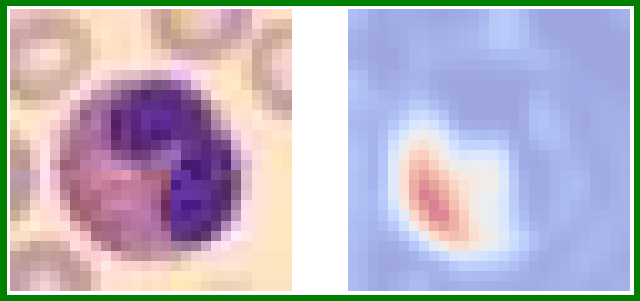

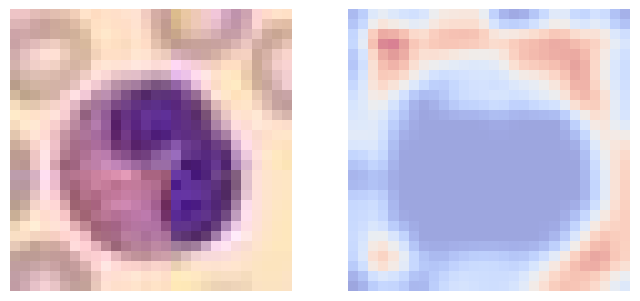

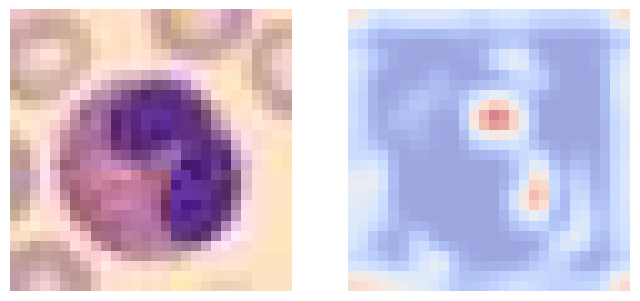

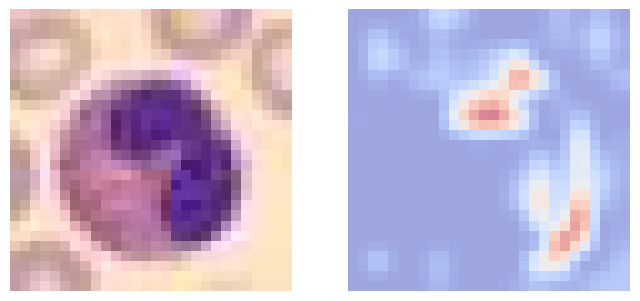

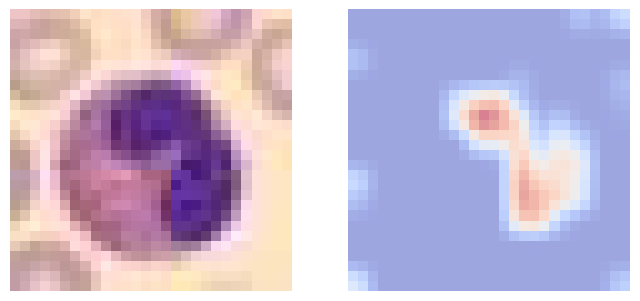

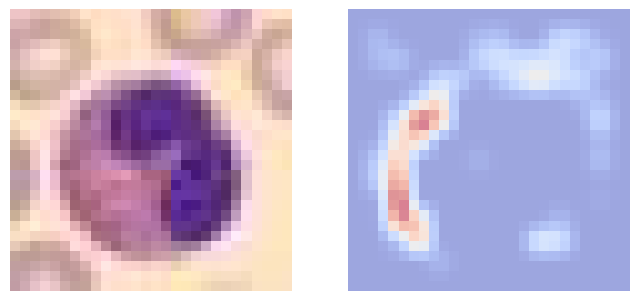

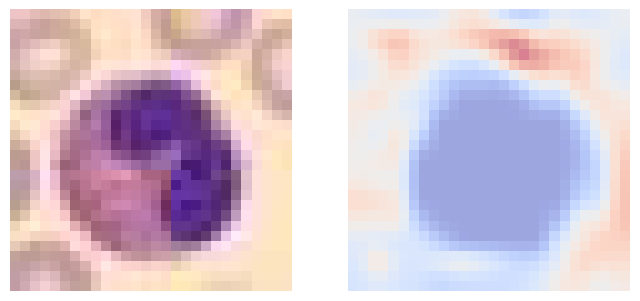

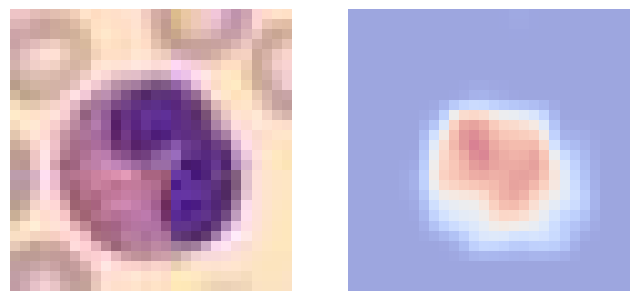

In [182]:
#jako pierwszy wyświetlany jest obraz z heatmapą dla prawdziwej klasy, następnie dla wszystkich błędnych klas
#w zielonej ramce jest heatmapa dla klasy przewidzianej przez model
ind = randint(0, len(X_test))
for i in range(8):
    plot_gradcam_heatmap(X_test[ind], (y_test[ind][0] + i) % 8)

## Oddanie zadania

Zapisz kod, wyniki, wykresy i uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i zadbaj o odtwarzalność rozwiązania. Umieść rozwiązania w swoim repozytorium.

źródła:
źródła podane wcześniej wykorzystane do gradcam
https://youtu.be/KuXjwB4LzSA?si=bABUn_uC5fAMCNNg
https://docs.pytorch.org/docs/2.15/index.html
https://docs.pytorch.org/vision/0.22/transforms.html
gemini użyty do lepszego zrozumienia architektury CNN i innych rzeczy związanych z tym zadaniem, szukania odpowiednich metod (np transformacji).
